In [1]:
import seabreeze
seabreeze.use("pyseabreeze")

import seabreeze.spectrometers as sb

#print(sb.list_devices())                  # should show ST:ST03283
#spec = sb.Spectrometer.from_serial_number("ST03283")

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import datetime
devices = sb.list_devices() 

In [3]:
print(f"Found {len(devices)} device(s): {devices}")

Found 1 device(s): [<SeaBreezeDevice ST:ST03283 >]


In [4]:
spec = sb.Spectrometer(devices[0])

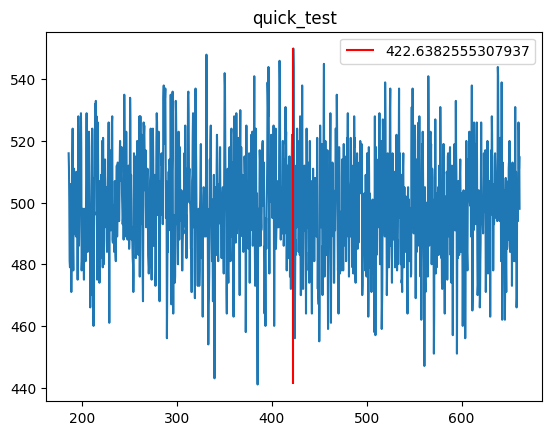

In [5]:
micro_time = .1*1e6
spec.integration_time_micros(micro_time)
nm,ints = spec.spectrum()
plt.plot(nm,ints)
# plt.plot(nm,ints-dark_)
plt.vlines(nm[np.argmax(ints)],np.min(ints),np.max(ints),color='r',label=nm[np.argmax(ints)])
plt.title('quick_test'.format(micro_time/1e3))
# plt.ylim(np.min(ints),np.max(ints))
plt.legend()

In [69]:
fish_dict = {
    'int_t':micro_time, # us
    'spectrum':ints,
    'wavelength':nm,
    'ts':datetime.datetime.now()
}


In [70]:
np.save('./AA_spectral_measurment_beforeSphere_wDarknoise600_cocktail.npy',fish_dict)

In [27]:
tomod = np.load("./AA_spectral_measurment_closerDistance_wDarknoise600_UV.npy",allow_pickle=True)

In [28]:
toSave= tomod.item()

In [29]:
del toSave['int_t']

In [30]:
toSave

{'spectrum': array([526., 541., 536., ..., 562., 575., 552.], shape=(1516,)),
 'wavelength': array([186.06072998, 186.41267789, 186.76456181, ..., 660.37952225,
        660.66446331, 660.94937982], shape=(1516,)),
 'ts': datetime.datetime(2026, 1, 23, 9, 41, 10, 738186)}

In [32]:
np.save('./AA_spectral_measurment_closerDistance_wDarknoise600_UV.npy',toSave)

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import time
#import pandas as pd

ModuleNotFoundError: No module named 'pandas'

In [2]:
# spec = sb.Spectrometer.from_serial_number("S03615")#STS-UV-L-100-400-SMA
# #set integration time
# micro_time=.2*1e6 # us
# spec.integration_time_micros(micro_time)

### load the calibrated aura3 blue & uv

In [2]:
stsuv = np.load('./aura3_stsuv100_calibration22122025_withguv_filters.npz')
stuv = np.load('./aura3_stuv100_calibration07012026_w_filters.npz')

In [4]:
nm = calibration['nm']
int_t = calibration['int_t']
uv_input = calibration['uv_input']
blue_input = calibration['blue_input']
dark_avg = calibration['dark_avg']
clean_uv = calibration['clean_uv']
clean_blue = calibration['clean_blue']

### load the green-filter datasheet

In [6]:
g_filter_path = './Green_filter_BP500-70K.xlsx'
df_g = pd.read_excel(g_filter_path,sheet_name="Sheet1")
df_g = pd.read_excel(g_filter_path)
g_filter_nm = df_g['Unnamed: 0']
g_filter_sensi = df_g['BP500-70K']

In [11]:
np.savez('./cam_g_filtered.npz',g_filter_nm=g_filter_nm,g_filter_sensi=g_filter_sensi)

In [13]:
uv_filter_path='./UV_filter_365nm.xlsx'
df_uv = pd.read_excel(uv_filter_path,sheet_name="Sheet2")
df_uv = pd.read_excel(uv_filter_path)
uv_filter_nm = df_uv['Unnamed: 0']
uv_filter_sensi = df_uv['Unnamed: 1']

In [14]:
np.savez('./cam_uv_filtered.npz',uv_filter_nm=uv_filter_nm,uv_filter_sensi=uv_filter_sensi)

### OLD plot the aura3 spectra and the filter parameters

In [58]:
nm = stsuv['nm']
int_t = stsuv['int_t']
uv_input = stsuv['uv_input']
blue_input = stsuv['blue_input']
dark_avg = stsuv['dark_avg']
clean_uv = stsuv['clean_uv']
clean_uv_filtered=stsuv['clean_uv_filtered']
clean_blue = stsuv['clean_blue']
clean_blue_filtered=stsuv['clean_blue_filtered']

In [59]:
blue_plot_inPerc = clean_blue/np.max(clean_blue)*100
blue_filtered_plot_inPerc=clean_blue_filtered/np.max(clean_blue_filtered)*100
uv_plot_inPerc = clean_uv/np.max(clean_uv)*100
uv_filtered_plot_inPerc=clean_uv_filtered/np.max(clean_uv_filtered)*100


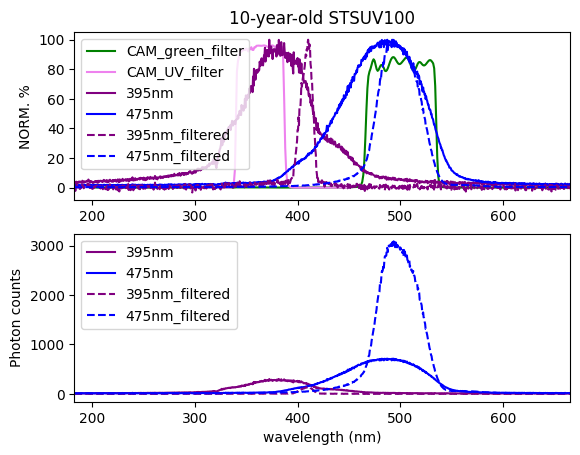

In [60]:
plt.subplot(211)
plt.plot(g_filter_nm,g_filter_sensi,color='green',label='CAM_green_filter')
plt.plot(uv_filter_nm,uv_filter_sensi,color='violet',label='CAM_UV_filter')

plt.plot(nm,uv_plot_inPerc,color='purple',label='395nm')
plt.plot(nm,blue_plot_inPerc,color='blue',label='475nm')

plt.plot(nm,uv_filtered_plot_inPerc,linestyle='dashed',color='purple',label='395nm_filtered')
plt.plot(nm,blue_filtered_plot_inPerc,linestyle='dashed',color='blue',label='475nm_filtered')

plt.ylabel('NORM. %')
plt.title('10-year-old STSUV100')
plt.legend()
plt.xlim(np.min(nm),np.max(nm))

plt.subplot(212)
plt.plot(nm,clean_uv,color='purple',label='395nm')
plt.plot(nm,clean_blue,color='blue',label='475nm')
plt.plot(nm,clean_uv_filtered,linestyle='dashed',color='purple',label='395nm_filtered')
plt.plot(nm,clean_blue_filtered,linestyle='dashed',color='blue',label='475nm_filtered')
plt.xlabel('wavelength (nm)')
plt.ylabel('Photon counts')
plt.legend()
plt.xlim(np.min(nm),np.max(nm))
plt.savefig('./old_STSUV.jpg')

In [61]:
nm = stuv['nm']
int_t = stuv['int_t']
uv_input = stuv['uv_input']
blue_input = stuv['blue_input']
dark_avg = stuv['dark_avg']
clean_uv = stuv['clean_uv']
clean_uv_filtered=stuv['clean_uv_filtered']
clean_blue = stuv['clean_blue']
clean_blue_filtered=stuv['clean_blue_filtered']

In [62]:
blue_plot_inPerc = clean_blue/np.max(clean_blue)*100
blue_filtered_plot_inPerc=clean_blue_filtered/np.max(clean_blue_filtered)*100
uv_plot_inPerc = clean_uv/np.max(clean_uv)*100
uv_filtered_plot_inPerc=clean_uv_filtered/np.max(clean_uv_filtered)*100


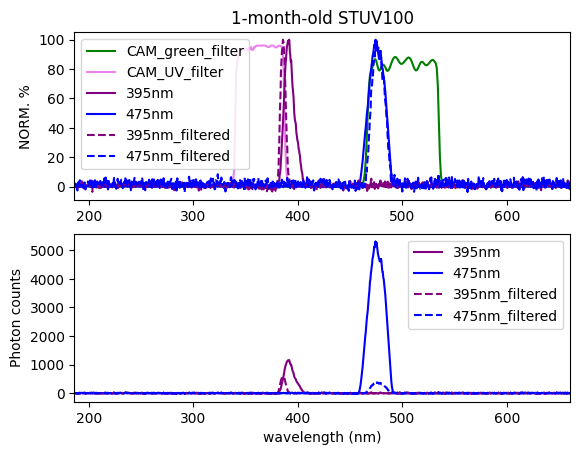

In [63]:
plt.subplot(211)
plt.plot(g_filter_nm,g_filter_sensi,color='green',label='CAM_green_filter')
plt.plot(uv_filter_nm,uv_filter_sensi,color='violet',label='CAM_UV_filter')

plt.plot(nm,uv_plot_inPerc,color='purple',label='395nm')
plt.plot(nm,blue_plot_inPerc,color='blue',label='475nm')

plt.plot(nm,uv_filtered_plot_inPerc,linestyle='dashed',color='purple',label='395nm_filtered')
plt.plot(nm,blue_filtered_plot_inPerc,linestyle='dashed',color='blue',label='475nm_filtered')

plt.ylabel('NORM. %')
plt.title('1-month-old STUV100')
plt.legend()
plt.xlim(np.min(nm),np.max(nm))

plt.subplot(212)
plt.plot(nm,clean_uv,color='purple',label='395nm')
plt.plot(nm,clean_blue,color='blue',label='475nm')
plt.plot(nm,clean_uv_filtered,linestyle='dashed',color='purple',label='395nm_filtered')
plt.plot(nm,clean_blue_filtered,linestyle='dashed',color='blue',label='475nm_filtered')
plt.xlabel('wavelength (nm)')
plt.ylabel('Photon counts')
plt.legend()
plt.xlim(np.min(nm),np.max(nm))
plt.savefig('./young_STUV.jpg')

### visualize the green-img-forming light 

In [33]:
# common x-grid over the overlap of both sts_uv_100 and cam_g_filters ranges
# take the sts range directly
x_min = max(nm.min(), g_filter_nm.min())
x_max = min(nm.max(), g_filter_nm.max())
x_common = np.linspace(x_min, x_max, 2000)
print(x_min,x_max)

200 665.6025696758672


In [38]:
# 2) interpolate all curves to the common grid
blue475_interpolated = np.interp(x_common, nm,blue_plot_inPerc )
cam_g_interpolated = np.interp(x_common, g_filter_nm,g_filter_sensi)
y_overlap = np.minimum(blue475_interpolated, cam_g_interpolated)
area_overlap = np.trapezoid(y_overlap, x_common)

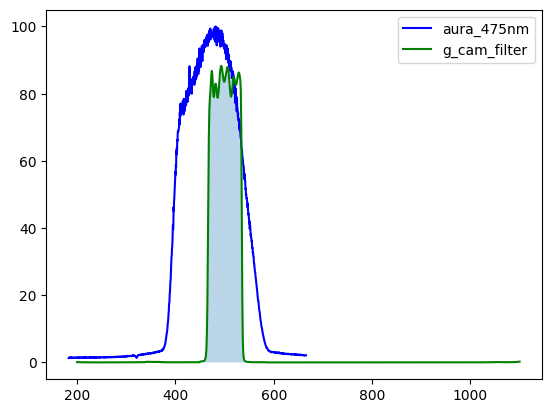

Overlapped areas under cam_g_filter: 0.5650249306480934


In [56]:
plt.plot(nm, blue_plot_inPerc, 'blue', label='aura_475nm')
plt.plot(g_filter_nm,g_filter_sensi, 'green', label='g_cam_filter')
plt.fill_between(x_common, 0, y_overlap, alpha=0.3)
plt.legend()
plt.title('
plt.show()

print("Overlapped areas under cam_g_filter:", area_overlap/100.0/100)

(186.06072998046875, 660.9493798151501)

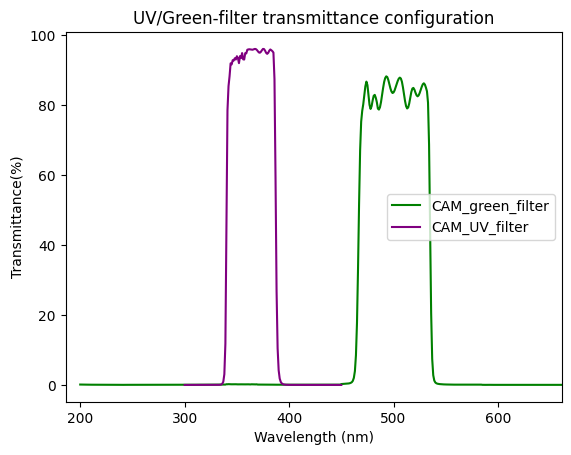

In [71]:
plt.plot(g_filter_nm,g_filter_sensi,color='green',label='CAM_green_filter')
plt.plot(uv_filter_nm,uv_filter_sensi,color='purple',label='CAM_UV_filter')

plt.ylabel('Transmittance(%)')
plt.xlabel('Wavelength (nm)')
plt.title('UV/Green-filter transmittance configuration')
plt.legend()
plt.xlim(np.min(nm),np.max(nm))


#plt.savefig('./young_STUV.jpg')

In [48]:
blue_aura3 = []
for _ in range(10):
    _,ints = spec.spectrum()
    blue_aura3.append(ints)
    time.sleep(6)
blue_aura3_200ms = np.mean(np.asarray(blue_aura3),axis=0)
clean_blue_aura3_200ms = blue_aura3_200ms-dark_200ms

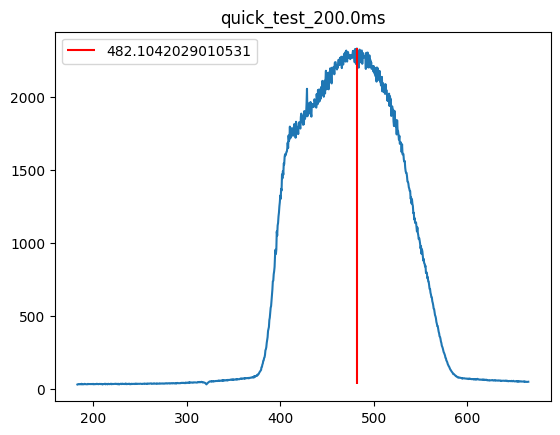

In [66]:
int_curve = np.copy(clean_blue_aura3_200ms)
plt.plot(nm,int_curve)
plt.vlines(nm[np.argmax(int_curve)],np.min(int_curve),np.max(int_curve),color='r',label=nm[np.argmax(int_curve)])
plt.title(f'quick_test_{micro_time/1e3}ms')
# plt.ylim(np.min(ints),np.max(ints))
plt.legend()

In [ ]:
uv_aura3 = []
for _ in range(10):
    _,ints = spec.spectrum()
    uv_aura3.append(ints)
    time.sleep(6)
uv_aura3_200ms = np.mean(np.asarray(uv_aura3),axis=0)
clean_uv_aura3_200ms = uv_aura3_200ms-dark_200ms

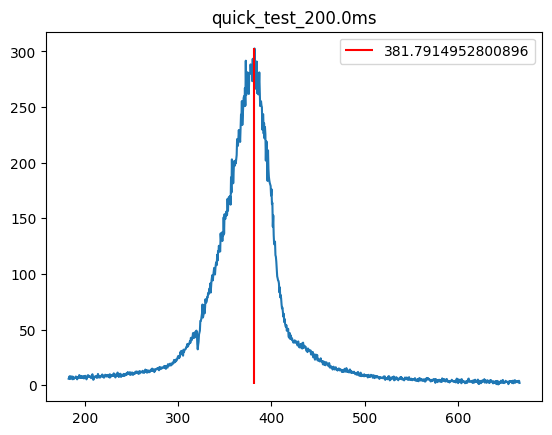

In [67]:
int_curve = np.copy(clean_uv_aura3_200ms)
plt.plot(nm,int_curve)
plt.vlines(nm[np.argmax(int_curve)],np.min(int_curve),np.max(int_curve),color='r',label=nm[np.argmax(int_curve)])
plt.title(f'quick_test_{micro_time/1e3}ms')
# plt.ylim(np.min(ints),np.max(ints))
plt.legend()

In [64]:
nm = nm
int_t = micro_time
uv_input = [(1,0,0),(0,0,1)]
blue_input = [(1,0,0),(0,3,0)]
dark_avg = dark_200ms
clean_uv = clean_uv_aura3_200ms
clean_blue = clean_blue_aura3_200ms

In [65]:
np.savez('./aura3_stsuv100_calibration22122025.npz',
         nm=nm,int_t=int_t,
         uv_input=uv_input,
         blue_input=blue_input,
         dark_avg=dark_avg,
         clean_uv=clean_uv,
         clean_blue=clean_blue)